In [2]:
import numpy as np
import matplotlib.pyplot as plt
import RateRegions.toolbox as funcs
import RateRegions.sim_funcs as sim
import pickle
import math

In [7]:
area_params = {"delta_h": 10 # height difference
                    , "area": 500  # lxl Service Area
                    , "bandwidth": 20e6
                    , "L": 64  # APs
                    , "N": 4  # antennas per AP
                    , "K": 6  # UEs
                    , "carrier_frequency": 2000  # carrier frequency (MHz)
                    , "sigma_sf_los": 8  # Shadow fading LoS (dB)
                    , "AP_pos_rand": False
                                     }

sim_params = {"setups": 1000,
                     "batch":200,
                     "v":-1,
                     "d": 0,   #rician factor (0: no LoS component)
                     "norm_type" : np.inf,
                     "tests" :50
                    }

In [15]:
filename = f"cdf_results_L64N4K6.pkl"
cdf_results = pickle.load(open(filename, "rb"))
invZ = cdf_results['invZ']
sumrate_hsdmS = cdf_results['sumrate_hsdmS']
sumrate_hsdmR = cdf_results['sumrate_hsdmR']
sumrate_hsdmC = cdf_results['sumrate_hsdmC']
sumrate_bcd = cdf_results['sumrate_bcd']
sumrate_maxPow = cdf_results['sumrate_maxPow']

sumrate_maxPow = np.array(sumrate_maxPow).flatten()

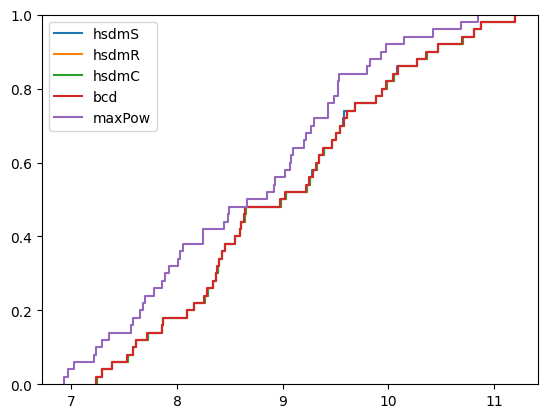

In [13]:
fig, ax = plt.subplots()
ax.ecdf(sumrate_hsdmS, label='hsdmS')
ax.ecdf(sumrate_hsdmR, label='hsdmR')
ax.ecdf(sumrate_hsdmC, label='hsdmC')
ax.ecdf(sumrate_bcd, label='bcd')
ax.ecdf(sumrate_maxPow, label='maxPow')

ax.legend()

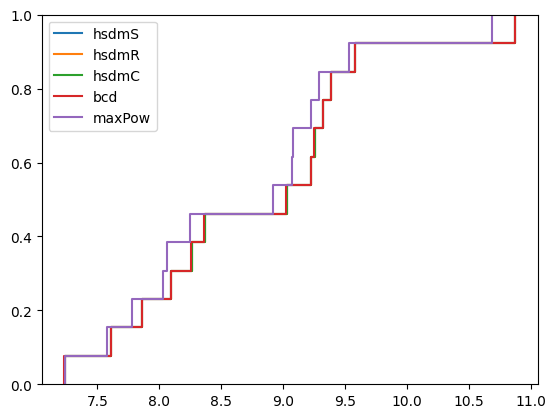

In [16]:
invZ_hsdmS = [sumrate for sumrate, inv in zip(sumrate_hsdmS, invZ) if inv]
invZ_hsdmR = [sumrate for sumrate, inv in zip(sumrate_hsdmR, invZ) if inv]
invZ_hsdmC = [sumrate for sumrate, inv in zip(sumrate_hsdmC, invZ) if inv]
invZ_bcd = [sumrate for sumrate, inv in zip(sumrate_bcd, invZ) if inv]
invZ_maxPow = [sumrate for sumrate, inv in zip(sumrate_maxPow, invZ) if inv]

fig, ax = plt.subplots()
ax.ecdf(invZ_hsdmS, label='hsdmS')
ax.ecdf(invZ_hsdmR, label='hsdmR')
ax.ecdf(invZ_hsdmC, label='hsdmC')
ax.ecdf(invZ_bcd, label='bcd')
ax.ecdf(invZ_maxPow, label='maxPow')

ax.legend()